# №5 зертханалық жұмыс
## Accuracy, Precision, Recall, F1-score, ROC-AUC метрикаларын және айқас тексеру әдістерін қолданып модельдерді бағалау.

Мақсат: арифметиканы, таңдауды және қорытынды бағалауды бөлу. Оң класс 1; болжам `p>=t`; құны FP+5FN. Барлық дерек жасанды. Байланыс: 5-тарау, 5.7–5.8-бөлімдер; `lab05.py`. Орта орнатылғаннан кейін сыртқы деректер жүктелмейді. Артефакттар `lab05_artifacts` ішінде сақталады.

Ұяшықтарды таза ядрода ретімен іске қосыңыз. Сақталған шығыс нақты тәжірибені көрсетеді; test жақсаруына алдын ала уәде берілмейді.

### Қадам 1 Келісімдер және орта
Шектік көрсеткіштер белгілерді; AUC, AP, Brier және log loss 1 класының бастапқы ықтималдықтарын алады. AP трапециялармен емес, average_precision_score арқылы есептеледі. Brier бинарлық 0–1 шкаласын қолданады. Анықталмаған Precision zero_division=0 арқылы нөлмен жазылады, мұны есепте түсіндіру қажет.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score, brier_score_loss,
    log_loss, precision_recall_curve, roc_curve, auc)

ROOT = Path.cwd() / "lab05_artifacts"
FIGURES, DATASETS = ROOT / "figures", ROOT / "datasets"
FIGURES.mkdir(parents=True, exist_ok=True)
DATASETS.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"

def label_metrics(y, p, threshold):
    prediction = (np.asarray(p)>=threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0,1]).ravel()
    return {"threshold": float(threshold), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "accuracy": accuracy_score(y,prediction),
            "precision": precision_score(y,prediction,pos_label=1,zero_division=0),
            "recall": recall_score(y,prediction,pos_label=1,zero_division=0),
            "F1": f1_score(y,prediction,pos_label=1,zero_division=0), "cost_FP1_FN5": int(fp+5*fn)}

def probability_metrics(y,p):
    return {"ROC_AUC": roc_auc_score(y,p), "AP": average_precision_score(y,p,pos_label=1),
            "Brier": brier_score_loss(y,p,pos_label=1,scale_by_half=True),
            "log_loss": log_loss(y,p,labels=[0,1])}

def make_model():
    return Pipeline([("scale",StandardScaler()),("model",LogisticRegression(C=1,max_iter=2000))])


from IPython.display import display, Image
from importlib.metadata import version
for package in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2


### 2–3-қадамдар Қолмен мысал
Сегіз жауап пен ықтималдық жасанды берілген. .5 және .3 екі шегі алдын ала көрсетілген, модель оқытылмайды. Матрицаларды, құнды және ықтималдық көрсеткіштерін қолмен есептеңіз. Сұрыптауда оң нысандар 1,3,4,6 рангтерінде орналасады, сондықтан AP=(1+2/3+3/4+4/6)/4=37/48.

In [2]:
def manual_experiment():
    y = np.array([0,1,0,1,1,0,1,0])
    p = np.array([.1,.9,.4,.7,.3,.2,.6,.8])
    rows = [label_metrics(y,p,t) for t in [.5,.3]]
    probabilities = probability_metrics(y,p)
    precision, recall, _ = precision_recall_curve(y,p,pos_label=1)
    trapezoid = auc(recall,precision)
    print("Жасанды қолмен есептеу мысалы\n",pd.DataFrame(rows).to_string(index=False))
    print("Ықтималдық көрсеткіштері",probabilities,"PR трапециялары",trapezoid)
    return {"synthetic_arithmetic":True,"y":y.tolist(),"p":p.tolist(),"thresholds":rows,
            **probabilities,"trapezoidal_PR_AUC":float(trapezoid)}


manual_result=manual_experiment()


Жасанды қолмен есептеу мысалы
  threshold  TN  FP  FN  TP  accuracy  precision  recall   F1  cost_FP1_FN5
       0.5   3   1   1   3      0.75   0.750000    0.75 0.75             6
       0.3   2   2   0   4      0.75   0.666667    1.00 0.80             2
Ықтималдық көрсеткіштері {'ROC_AUC': 0.75, 'AP': 0.7708333333333333, 'Brier': 0.2, 'log_loss': 0.5782001863575765} PR трапециялары 0.73125


Екі ереженің де Accuracy мәні .75-ке тең, құны 6-дан 2-ге өзгереді. AUC=.75, AP=.770833, PR трапециялары=.73125, Brier=.2, log loss=.578200. Әртүрлі шек осы ықтималдық көрсеткіштерін өзгертпейді.

**Сіздің жауабыңыз.** Құн өзгерісін бір FN түзетілуі және бір FP қосылуы ретінде көрсетіңіз. Теңдік келісімі мен AP-дің трапециялардан айырмасын түсіндіріңіз.

_Өз есебіңізді жазыңыз._

### Қадам 4 Синтетикалық деректердің үш бөлігі
make_classification: 1000 жол, 20 белгі, 5 ақпаратты, 2 артық; weights=[.9,.1], class_sep=1.2, flip_y=.02, seed=2026. Алдымен стратификация және seed 2026 арқылы 80/20, кейін 800 ішінде стратификация және seed 2027 арқылы 75/25. 600 train, 200 validation, 200 test алынады. Test шешім бекітілгенге дейін зерттелмейді.

In [3]:
def make_split():
    raw, target = make_classification(n_samples=1000,n_features=20,n_informative=5,
        n_redundant=2,weights=[.9,.1],class_sep=1.2,flip_y=.02,random_state=2026)
    X, y = pd.DataFrame(raw,columns=[f"x{i}" for i in range(20)]),pd.Series(target,name="target")
    Xdev,Xtest,ydev,ytest = train_test_split(X,y,test_size=.2,stratify=y,random_state=2026)
    Xtrain,Xval,ytrain,yval = train_test_split(Xdev,ydev,test_size=.25,stratify=ydev,random_state=2027)
    return {"X":X,"y":y,"train":(Xtrain,ytrain),"validation":(Xval,yval),"test":(Xtest,ytest)}


split=make_split()
print("Бөлік көлемдері:",{name:len(split[name][1]) for name in ["train","validation","test"]})
print("Тек train/validation оң нысандары:",{name:int(split[name][1].sum()) for name in ["train","validation"]})


Бөлік көлемдері: {'train': 600, 'validation': 200, 'test': 200}
Тек train/validation оң нысандары: {'train': 64, 'validation': 22}


### Қадам 5 Тек train ішіндегі бөлек CV
Бес стратификацияланған бүктеме, shuffle=True, seed=2028; конвейерлер рұқсат етілген бөліктер ішінде қайта оқытылады. Бекітілген ROC-AUC және AP бағаланады. Бұл — параметр не шек таңдаусыз шашырауды көрсету. Бес бағаның стандартты ауытқуы сенімділік аралығы деп жарияланбайды.

In [4]:
def train_cv(split):
    Xtrain,ytrain = split["train"]
    cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=2028)
    scores = cross_validate(make_model(),Xtrain,ytrain,cv=cv,n_jobs=1,
                            scoring={"ROC_AUC":"roc_auc","AP":"average_precision"})
    result = {name:{"fold_scores":scores[f"test_{name}"].tolist(),
                    "mean":float(scores[f"test_{name}"].mean()),
                    "std_fold_ddof1":float(scores[f"test_{name}"].std(ddof=1))}
              for name in ["ROC_AUC","AP"]}
    print("Тек 600 train жолындағы бөлек CV, баптаулар таңдалмайды:",result)
    return result


cv_result=train_cv(split)


Тек 600 train жолындағы бөлек CV, баптаулар таңдалмайды: {'ROC_AUC': {'fold_scores': [0.8569374550682962, 0.6462976276060388, 0.7972681524083394, 0.7541337167505392, 0.7878086419753086], 'mean': 0.7684891187617044, 'std_fold_ddof1': 0.07771972566212901}, 'AP': {'fold_scores': [0.49189107039685426, 0.5000377362687833, 0.40994119704789483, 0.31177847205451736, 0.32829179214982623], 'mean': 0.40838805358357516, 'std_fold_ddof1': 0.08820948467529158}}


### 6–7-қадамдар Оқыту және шек таңдау
Негізгі Pipeline: StandardScaler+LogisticRegression(C=1,max_iter=2000), fit тек 600 train жолында. DummyPrior сонда оқытылады. Кандидаттар: [0] + бірегей validation ықтималдықтары + [1]. FP+5FN азайтылады; құн тең болса, үлкенірек шек таңдалады. Таңдаудан кейін модель 800 жолда қайта оқытылмайды.

In [5]:
def fit_and_select(split):
    Xtrain,ytrain = split["train"]
    Xval,yval = split["validation"]
    model,dummy = make_model(),DummyClassifier(strategy="prior")
    model.fit(Xtrain,ytrain)
    dummy.fit(Xtrain,ytrain)
    pval = model.predict_proba(Xval)[:,1]
    thresholds = np.unique(np.r_[0.,pval,1.])
    candidates = [label_metrics(yval,pval,float(t)) for t in thresholds]
    selected = min(candidates,key=lambda row:(row["cost_FP1_FN5"],-row["threshold"]))
    print("Тек validation бойынша таңдалды:",selected)
    return {"model":model,"dummy":dummy,"pval":pval,"candidates":candidates,"selected":selected,
            "coefficients_after_fit":model.named_steps["model"].coef_.copy()}


state=fit_and_select(split)
print("Модель оқытылған жол саны:",state["model"].named_steps["scale"].n_samples_seen_,"жол")


Тек validation бойынша таңдалды: {'threshold': 0.1331864338959544, 'TN': 147, 'FP': 31, 'FN': 6, 'TP': 16, 'accuracy': 0.815, 'precision': 0.3404255319148936, 'recall': 0.7272727272727273, 'F1': 0.463768115942029, 'cost_FP1_FN5': 61}
Модель оқытылған жол саны: 600.0 жол


### 8–9-қадамдар Бекітуден кейінгі тәуелсіз test
Енді ықтималдықтар мен үш ереженің нәтижелері есептеледі: Dummy .5, Logistic .5 және бекітілген validation шегі бар Logistic. Бірдей логистикалық ықтималдықтар екі шек үшін де қолданылады. ROC/PR test бойынша кейінгі таңдаусыз құрылады; шектер құны validation бойынша есептеледі. Test диагностикасы саны көрсетілген алдын ала бекітілген бес аралықты қолданады.

Бір бекітілген test
                  rule  threshold  TN  FP  FN  TP  accuracy  precision   recall       F1  cost_FP1_FN5
           Dummy t=.5   0.500000 179   0  21   0     0.895     0.0000 0.000000 0.000000           105
        Logistic t=.5   0.500000 175   4  20   1     0.880     0.2000 0.047619 0.076923           104
Logistic t=validation   0.133186 140  39  12   9     0.745     0.1875 0.428571 0.260870            99
Сол ықтималдықтардың көрсеткіштері
      model  ROC_AUC       AP    Brier  log_loss
DummyPrior 0.500000 0.105000 0.093978  0.335947
  Logistic 0.631285 0.248304 0.093589  0.361047


Калибрлеу диагностикасы, 5 бекітілген аралық: [{'lower': 0.0, 'upper': 0.2, 'n': 169, 'mean_probability': 0.058888947697030895, 'positive_fraction': 0.08875739644970414}, {'lower': 0.2, 'upper': 0.4, 'n': 21, 'mean_probability': 0.2596126062046245, 'positive_fraction': 0.047619047619047616}, {'lower': 0.4, 'upper': 0.6000000000000001, 'n': 7, 'mean_probability': 0.4754757703392046, 'positive_fraction': 0.5714285714285714}, {'lower': 0.6000000000000001, 'upper': 0.8, 'n': 3, 'mean_probability': 0.698303097727039, 'positive_fraction': 0.3333333333333333}, {'lower': 0.8, 'upper': 1.0, 'n': 0, 'mean_probability': None, 'positive_fraction': None}]


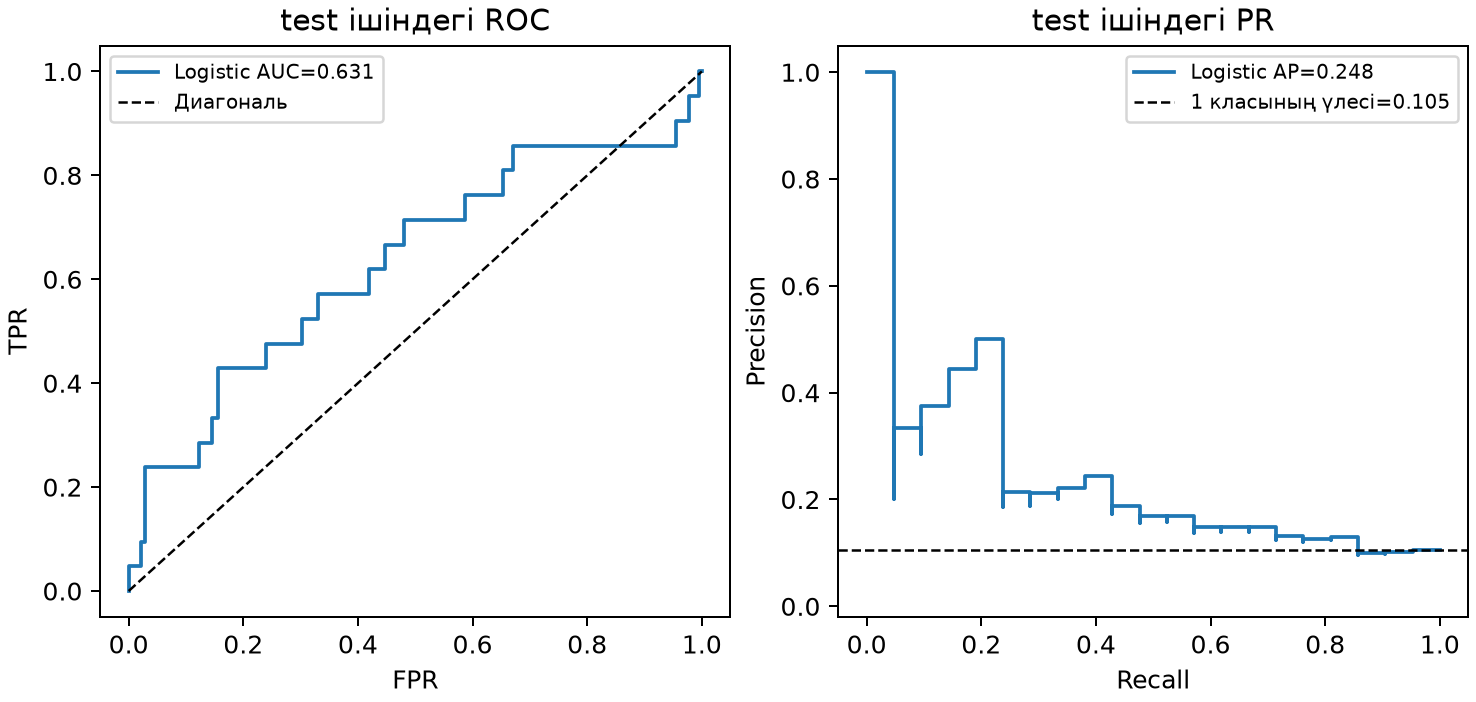

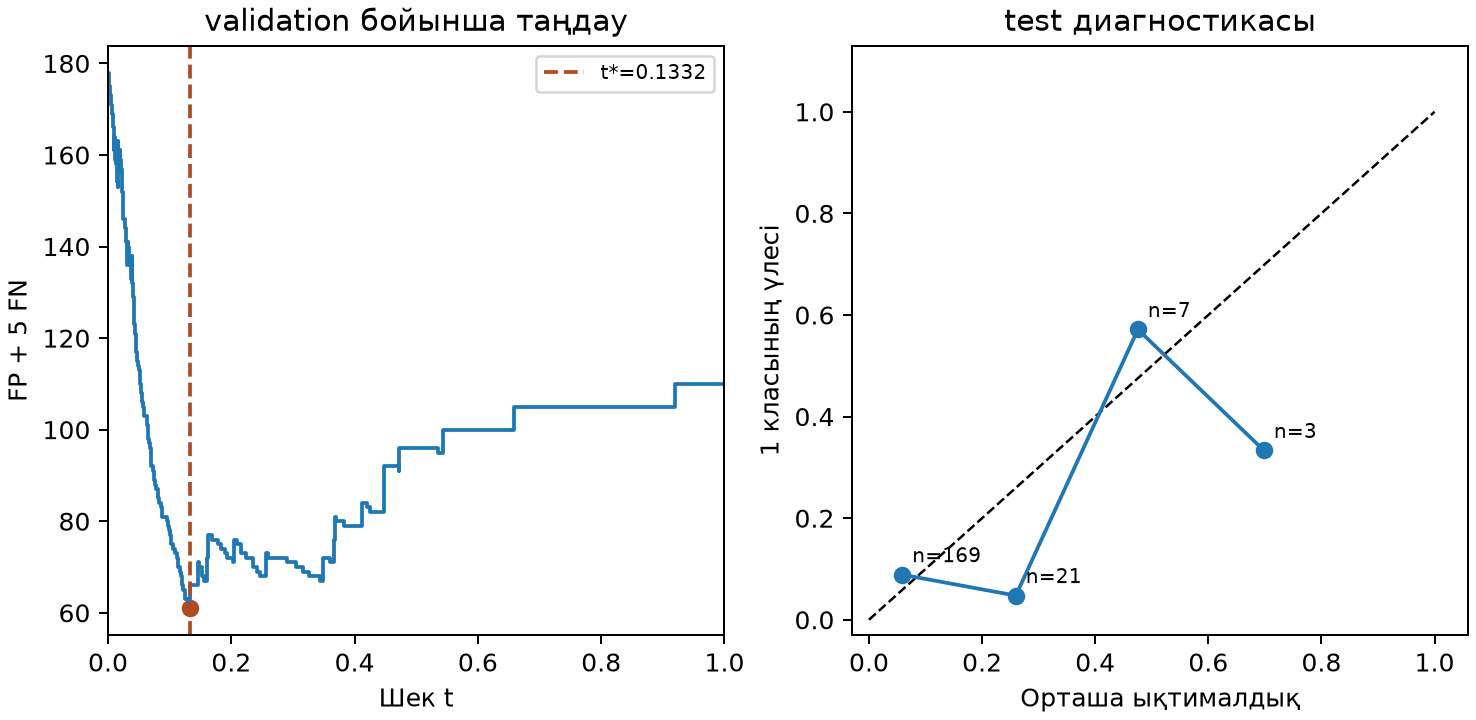

In [6]:
def test_experiment(split,state):
    Xtest,ytest = split["test"]
    p = state["model"].predict_proba(Xtest)[:,1]
    pdummy = state["dummy"].predict_proba(Xtest)[:,1]
    chosen = state["selected"]["threshold"]
    rows = [{"rule":"Dummy t=.5",**label_metrics(ytest,pdummy,.5)},
            {"rule":"Logistic t=.5",**label_metrics(ytest,p,.5)},
            {"rule":"Logistic t=validation",**label_metrics(ytest,p,chosen)}]
    probs = [{"model":"DummyPrior",**probability_metrics(ytest,pdummy)},
             {"model":"Logistic",**probability_metrics(ytest,p)}]
    print("Бір бекітілген test\n",pd.DataFrame(rows).to_string(index=False))
    print("Сол ықтималдықтардың көрсеткіштері\n",pd.DataFrame(probs).to_string(index=False))
    fig,axs = plt.subplots(1,2,figsize=(8.2,3.9),layout="constrained")
    fpr,tpr,_ = roc_curve(ytest,p,pos_label=1)
    precision,recall,_ = precision_recall_curve(ytest,p,pos_label=1)
    axs[0].plot(fpr,tpr,label=f"Logistic AUC={probs[1]['ROC_AUC']:.3f}")
    axs[0].plot([0,1],[0,1],"k--",linewidth=1,label="Диагональ")
    axs[0].set(xlabel="FPR",ylabel="TPR",title="test ішіндегі ROC")
    axs[1].step(recall,precision,where="post",label=f"Logistic AP={probs[1]['AP']:.3f}")
    axs[1].axhline(float(ytest.mean()),linestyle="--",color="black",linewidth=1,
                   label=f"1 класының үлесі={ytest.mean():.3f}")
    axs[1].set(xlabel="Recall",ylabel="Precision",title="test ішіндегі PR",ylim=(-.02,1.05))
    axs[0].legend(fontsize=8);axs[1].legend(fontsize=8)
    fig.savefig(FIGURES/"ch05_05_roc_pr.png",dpi=180);plt.close(fig)
    edges = np.linspace(0,1,6)
    assignments = np.searchsorted(edges[1:-1],p,side="right")
    bins=[]
    for j in range(5):
        mask=assignments==j
        bins.append({"lower":float(edges[j]),"upper":float(edges[j+1]),"n":int(mask.sum()),
                     "mean_probability":float(p[mask].mean()) if mask.any() else None,
                     "positive_fraction":float(ytest.to_numpy()[mask].mean()) if mask.any() else None})
    fig,axs=plt.subplots(1,2,figsize=(8.2,4.0),layout="constrained")
    axs[0].step([r["threshold"] for r in state["candidates"]],
                [r["cost_FP1_FN5"] for r in state["candidates"]],where="pre")
    axs[0].axvline(chosen,color="#B34B20",linestyle="--",label=f"t*={chosen:.4f}")
    axs[0].scatter([chosen],[state["selected"]["cost_FP1_FN5"]],color="#B34B20")
    axs[0].set(xlabel="Шек t",ylabel="FP + 5 FN",title="validation бойынша таңдау",xlim=(0,1))
    axs[0].legend(fontsize=8)
    nonempty=[r for r in bins if r["n"]]
    axs[1].plot([0,1],[0,1],"k--",linewidth=1)
    axs[1].plot([r["mean_probability"] for r in nonempty],
                [r["positive_fraction"] for r in nonempty],"o-")
    for r in nonempty:
        axs[1].annotate(f"n={r['n']}",(r["mean_probability"],r["positive_fraction"]),
                        xytext=(4,5),textcoords="offset points",fontsize=8)
    axs[1].set(xlabel="Орташа ықтималдық",ylabel="1 класының үлесі",
               title="test диагностикасы",xlim=(-.03,1.06),ylim=(-.03,1.13))
    fig.savefig(FIGURES/"ch05_06_validation_calibration.png",dpi=180);plt.close(fig)
    print("Калибрлеу диагностикасы, 5 бекітілген аралық:",bins)
    split_names=pd.Series("",index=split["X"].index)
    for name in ["train","validation","test"]:
        split_names.loc[split[name][0].index]=name
    split["X"].assign(target=split["y"],split=split_names).to_csv(
        DATASETS/"synthetic_classification_validation.csv",index=False)
    memberships=[set(split[name][0].index) for name in ["train","validation","test"]]
    return {"synthetic":True,"rows":1000,"features":20,"sizes":[600,200,200],
            "positive_counts":{name:int(split[name][1].sum()) for name in ["train","validation","test"]},
            "selected_validation":state["selected"],"validation_candidates":state["candidates"],
            "test_threshold_rows":rows,"test_probability_metrics":probs,"test_calibration_bins":bins,
            "main_model_fit_rows":int(state["model"].named_steps["scale"].n_samples_seen_),
            "model_unchanged_after_selection":bool(np.array_equal(state["coefficients_after_fit"],state["model"].named_steps["model"].coef_)),
            "splits_disjoint":all(not memberships[i]&memberships[j] for i in range(3) for j in range(i)),
            "threshold_tie_rule":"largest threshold among minimum-cost candidates", "refit_on_800":False}


experiment_result=test_experiment(split,state)
display(Image(filename=str(FIGURES/"ch05_05_roc_pr.png")))
display(Image(filename=str(FIGURES/"ch05_06_validation_calibration.png")))


Тексерілген тәжірибеде t*=.1331864338959544, validation құны 61-ге тең. Test құны: Dummy — 105, .5 кезіндегі Logistic — 104, таңдалған шек — 99. Логистикалық модельдің Accuracy мәні .88-ден .745-ке азаяды. ROC-AUC=.631285, AP=.248304, Brier=.093589, log loss=.361047. Dummy-дің log loss мәні кіші: .335947. Диагностикалық аралықтар 169, 21, 7, 3, 0 нысанды қамтиды; бос аралықта нүкте жоқ.

**Сіздің жауабыңыз.** Құнның шағын үнемін, FP өсуін, validation/test айырмасын және үш бақылауы бар диаграмманың шектеуін түсіндіріңіз. Бұл нәтиже бойынша модельді немесе seed-ті өзгертпеңіз.

_Өз түсіндірмеңізді жазыңыз._

### Сандық өзін-өзі тексеру
Қолмен арифметика, кандидат таңдау ережесі, көлемдер, бөліктердің қиылыспауы және негізгі модельдің қайта оқытылмауы тексеріледі. Бұл зерттеу қорытындысының сапасын толық бағалау емес.

In [7]:
assert np.isclose(manual_result["ROC_AUC"],.75)
assert np.isclose(manual_result["AP"],37/48)
assert not np.isclose(manual_result["AP"],manual_result["trapezoidal_PR_AUC"])
assert np.isclose(manual_result["Brier"],.2)
assert [r["cost_FP1_FN5"] for r in manual_result["thresholds"]]==[6,2]
expected=min(state["candidates"],key=lambda row:(row["cost_FP1_FN5"],-row["threshold"]))
assert state["selected"]==expected
assert experiment_result["sizes"]==[600,200,200]
assert experiment_result["splits_disjoint"]
assert experiment_result["main_model_fit_rows"]==600
assert experiment_result["model_unchanged_after_selection"] and not experiment_result["refit_on_800"]
for row in experiment_result["test_threshold_rows"]:
    assert sum(row[k] for k in ["TN","FP","FN","TP"])==200
    assert row["cost_FP1_FN5"]==row["FP"]+5*row["FN"]
assert sum(r["n"] for r in experiment_result["test_calibration_bins"])==200
assert len(cv_result["AP"]["fold_scores"])==5
print("Арифметика мен хаттаманың өзін-өзі тексеруі өтті.")


Арифметика мен хаттаманың өзін-өзі тексеруі өтті.


### Жеке нұсқалар
Базалық test сақталады. Зерттеулерді ішкі оқыту тексеруінде немесе алдын ала бөлінген жаңа validation бойынша ұйымдастырыңыз.

1. FN3 және FN5 құндары.
2. train ішіндегі үш және бес CV бүктемесі.
3. Алдын ала берілген екі регуляризация күші және одан кейінгі бөлек шек таңдау.
4. Құнның бірнеше тең минимумы мен үлкенірек шек ережесінің жасанды мысалы.
5. Сандары көрсетілген бірқалыпты және квантильдік аралықтар.
6. Ішкі тексерудің FP/FN талдауы және бір шешімнің құнға үлесі.

**Сіздің нұсқаңыз, сұрағыңыз, өзгермейтін шарттарыңыз, критерийіңіз және қорытындыңыз.**

_Өз түсіндірмелеріңіз бен кодыңызды қосыңыз._

### Қадам 10 Есеп және қорғау
Келісімдер, қолмен есептеулер, генератор, split, барлық CV бағалары, шек дереккөзі, 600 train-дегі өзгермеген модель, екі кесте, екі сурет, нысандар саны, нұсқалар және таза іске қосу. CSV ішіндегі split өрісі қызметтік, белгі ретінде берілмейді.

Жергілікті рубрика: қойылым — 15%; арифметика — 20%; бөлу/CV — 20%; шек — 20%; түсіндіру — 15%; қайталанымдылық — 10%. Барлығы 100% толықтық, ресми балдарды силлабус пен оқытушы анықтайды.

Бақылау сұрақтары: test-ке дейінгі құн; шекке теңдік; бірдей Accuracy; өзгермейтін ықтималдық көрсеткіштері; AP/трапециялар; анықталмаған Precision; CV ішіндегі оқыту; validation минимумы; шағын аралықтар; 800-де қайта оқыту және шек.

Дереккөздер: Оспан Ә.Ғ. авторлық 5-дәрісі/5-ЗЖ; [AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), [Brier](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html), [шек таңдау](https://scikit-learn.org/stable/modules/classification_threshold.html), [диагностика](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.calibration_curve.html). 2026 жылғы 4 қарашада тексерілген.